# Pose training frames (DeepLabCut)

This notebook reviews the DeepLabCut training frames of one converted session. The source is the
training dataset of the model that produced the pose estimates
(`training-datasets/iteration-0/UnaugmentedDataSet_J20_FVBApr30/CollectedData_SB.h5`), which holds the
body-part positions labeled by hand on about 15 frames from each of 30 videos. Only sessions whose video
was labeled carry these frames. In NWB they are stored with the ndx-pose extension, and each frame links
to the session's video by frame index, so the image itself is read from the video.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import ndx_pose  # noqa: F401
import numpy as np
import pandas as pd
from hdmf.container import Container
from pynwb import NWBHDF5IO

In [2]:
nwb_file_path = Path("~/conversion_nwb/palop-lab-to-nwb/sub-63_ses-MetaSession3.nwb").expanduser()
training_file_path = Path(
    "/Volumes/seagate_0/vame/J20/training-datasets/iteration-0/UnaugmentedDataSet_J20_FVBApr30/CollectedData_SB.h5"
)

io = NWBHDF5IO(nwb_file_path, "r")
nwbfile = io.read()
behavior = nwbfile.processing["behavior"]
pose_training = behavior["PoseTraining"]
training_frames = pose_training.training_frames.training_frames
pose_estimation = behavior["PoseEstimationDeepLabCut"]
bodyparts = list(pose_estimation.skeleton.nodes[:])

## NWB objects for this stream

In [3]:
summary = pd.DataFrame(
    [
        dict(
            name=neurodata_object.name,
            neurodata_type=neurodata_object.neurodata_type,
            namespace=neurodata_object.namespace,
            parent=neurodata_object.parent.name,
        )
        for neurodata_object in nwbfile.objects.values()
        if isinstance(neurodata_object, Container) and neurodata_object.parent is not None
    ]
)
first_frame_name = sorted(training_frames)[0]
stream_object_names = ["PoseTraining", "training_frames", first_frame_name, "skeleton_instances", "skeleton_instance"]
summary[summary["name"].isin(stream_object_names)].drop_duplicates(["name", "neurodata_type"])

,name,neurodata_type,namespace,parent
5,PoseTraining,PoseTraining,ndx-pose,behavior
6,training_frames,TrainingFrames,ndx-pose,PoseTraining
8,skeleton_instances,SkeletonInstances,ndx-pose,frame_9794
9,skeleton_instance,SkeletonInstance,ndx-pose,skeleton_instances
49,frame_19593,TrainingFrame,ndx-pose,training_frames


Training frames should use ndx-pose: a `PoseTraining` container in the `behavior` processing module
holding `TrainingFrames`, one `TrainingFrame` per labeled frame. Each frame holds one `SkeletonInstance`
(a single animal) linked to the same `Skeleton` as the pose estimates, and links to the `BehaviorVideo`
`ImageSeries` through `source_video` and `source_video_frame_index`.

In [4]:
rows = []
for name, training_frame in training_frames.items():
    skeleton_instance = training_frame.skeleton_instances.skeleton_instances["skeleton_instance"]
    rows.append(
        dict(
            name=name,
            frame_index=int(training_frame.source_video_frame_index),
            annotator=training_frame.annotator,
            source_video=training_frame.source_video.name,
            skeleton=skeleton_instance.skeleton.name,
            visible_nodes=int(skeleton_instance.node_visibility[:].sum()),
        )
    )
training_table = pd.DataFrame(rows).sort_values("frame_index").set_index("frame_index")
training_table

,name,annotator,source_video,skeleton,visible_nodes
frame_index,,,,,
4016,frame_4016,Shreya Bangera,BehaviorVideo,Skeleton,11
9794,frame_9794,Shreya Bangera,BehaviorVideo,Skeleton,11
19593,frame_19593,Shreya Bangera,BehaviorVideo,Skeleton,11
24012,frame_24012,Shreya Bangera,BehaviorVideo,Skeleton,11
26992,frame_26992,Shreya Bangera,BehaviorVideo,Skeleton,11
29337,frame_29337,Shreya Bangera,BehaviorVideo,Skeleton,11
30936,frame_30936,Shreya Bangera,BehaviorVideo,Skeleton,11
45971,frame_45971,Shreya Bangera,BehaviorVideo,Skeleton,7
51138,frame_51138,Shreya Bangera,BehaviorVideo,Skeleton,11


## Labels and predictions on the video frames

Circles are the hand labels, crosses are the DeepLabCut predictions for the same frame.

In [5]:
def read_frame(video_path: Path, frame_index: int):
    capture = cv2.VideoCapture(str(video_path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = capture.read()
    capture.release()
    if not success:
        raise IOError(f"Could not read frame {frame_index} from {video_path}.")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


def get_labels(frame_index: int) -> np.ndarray:
    training_frame = training_frames[training_table.loc[frame_index, "name"]]
    return training_frame.skeleton_instances.skeleton_instances["skeleton_instance"].node_locations[:]


def get_predictions(frame_index: int) -> np.ndarray:
    return np.stack([pose_estimation.pose_estimation_series[bodypart].data[frame_index] for bodypart in bodyparts])

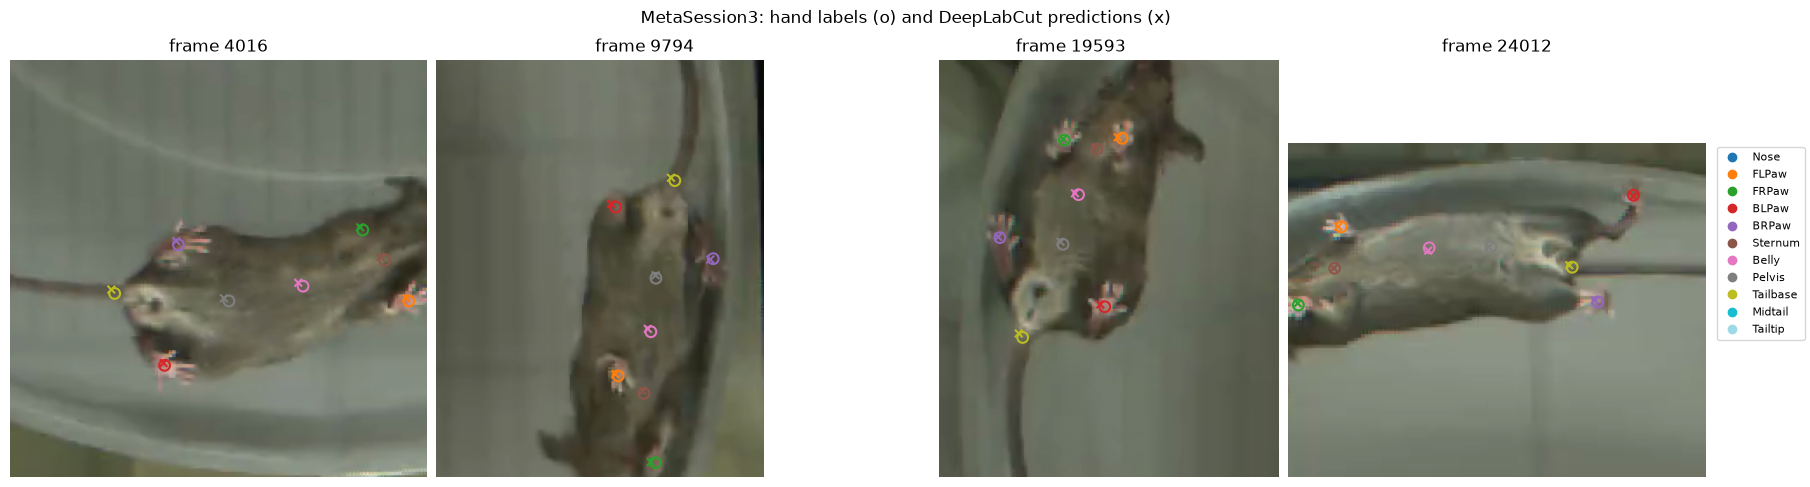

In [6]:
video_path = nwb_file_path.parent / pose_estimation.source_video.external_file[0]
colors = plt.cm.tab20(np.linspace(0, 1, len(bodyparts)))
frame_indices = training_table.index[:4]

fig, axes = plt.subplots(1, len(frame_indices), figsize=(18, 5), constrained_layout=True)
for ax, frame_index in zip(axes, frame_indices):
    labels, predictions = get_labels(frame_index), get_predictions(frame_index)
    ax.imshow(read_frame(video_path, frame_index))
    ax.scatter(labels[:, 0], labels[:, 1], s=60, facecolors="none", edgecolors=colors, linewidths=1.5)
    ax.scatter(predictions[:, 0], predictions[:, 1], s=30, marker="x", c=colors)
    center = np.nanmean(labels, axis=0)
    ax.set_xlim(center[0] - 120, center[0] + 120)
    ax.set_ylim(center[1] + 120, center[1] - 120)
    ax.set_title(f"frame {frame_index}")
    ax.axis("off")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=color, label=bp) for bp, color in zip(bodyparts, colors)]
fig.legend(handles=handles, loc="outside right center", fontsize=8)
fig.suptitle(f"{nwbfile.session_id}: hand labels (o) and DeepLabCut predictions (x)")
plt.show()

## Distance between labels and predictions

Most of these frames were in the model's training set, so the distances should be close to the train
error reported by DeepLabCut (2.06 px).

In [7]:
errors = pd.DataFrame(
    [np.linalg.norm(get_labels(frame_index) - get_predictions(frame_index), axis=1) for frame_index in training_table.index],
    index=training_table.index,
    columns=bodyparts,
)
errors.median().round(2).to_frame("median error (px)").T

,Nose,FLPaw,FRPaw,BLPaw,BRPaw,Sternum,Belly,Pelvis,Tailbase,Midtail,Tailtip
median error (px),1.55,1.98,1.68,2.04,1.76,1.48,2.21,1.86,2.12,1.91,1.48


## Check against the source file

Every labeled position in NWB should equal the training dataset, with unlabeled body parts stored as
NaN and marked not visible.

In [8]:
source_labels = pd.read_hdf(training_file_path)
source_labels = source_labels[source_labels.index.get_level_values(1) == "MetaSession3"]
source_frame_indices = [int(Path(image).stem.removeprefix("img")) for image in source_labels.index.get_level_values(2)]
source_locations = source_labels.to_numpy().reshape(len(source_labels), len(bodyparts), 2)

assert sorted(source_frame_indices) == list(training_table.index)
for frame_index, locations in zip(source_frame_indices, source_locations):
    training_frame = training_frames[training_table.loc[frame_index, "name"]]
    skeleton_instance = training_frame.skeleton_instances.skeleton_instances["skeleton_instance"]
    assert np.array_equal(skeleton_instance.node_locations[:], locations, equal_nan=True)
    assert np.array_equal(skeleton_instance.node_visibility[:], ~np.isnan(locations).any(axis=1))
print(f"All {len(source_frame_indices)} training frames match the source.")

All 15 training frames match the source.


In [9]:
io.close()